# 사례 분석: 수원 삼성 — 강등해도 관중을 지키는 구단은 무엇이 다른가

수원 삼성은 2023시즌 K리그1 최하위로 강등됐지만, K리그2에서도 홈 관중이 줄지 않았다(2026시즌 경기당 약 1만 6천 명).
이 노트북은 수원이 얼마나 예외적인지, 그리고 K리그2에서 관중이 성적에 어떻게 반응하는지 본다.

설계는 결과를 보기 전에 `CLAUDE.md` '다음 할 일 5'에 적어 두었다.
1. 리그가 바뀐 구단 8곳의 관중 변화 비교 (수원은 얼마나 예외적인가)
2. 전체 구단 모형: K리그2에서 홈팀 성적과 관중의 관계가 다른가
3. 수원 홈경기만 본 모형 (64경기, 탐색적)

## 요약

1. **강등 직후에는 수원도 리그 흐름을 따라가지 못했다:** 강등 첫해(2024) 관중은 −5%로 강등 구단 4곳 중 가장 적게 줄었지만, 같은 해 리그를 유지한 구단들은 중앙값 +23% 늘어 상대적으로는 28%p 뒤처졌다. 수원의 '관중 유지'는 강등 3년차인 2026년(2023년 대비 +36%)에 두드러진다.
2. **K리그2 시절 수원 관중은 성적에 거의 반응하지 않았다:** 수원 홈경기만 본 모형에서 최근 5경기 경기당 승점 +1점의 관중 차이는 +2%(95% 구간 −9%~+15%)였다. 대신 주말(+71%), 원정 팬 동원력이 높은 상대(log +1당 +17%, 수원 모형 기준), 더비(+21%, p≈0.06)와 관련이 컸다. 전체 구단 모형에서도 K리그2의 성적 민감도(+4%)는 K리그1(+9%)보다 작았지만 차이는 통계적으로 뚜렷하지 않았다(p=0.28).
3. **시사점:** 강등 구단에게 관중을 지키는 힘은 성적보다 '고정 팬층'과 '경기 자체의 매력(주말·인기 상대·더비)'에서 나온다. 성적으로 관중을 끌기 어려운 시기일수록 일정·상대팀에 맞춘 마케팅이 중요할 수 있다(구체적 방법은 다른 리그 사례로 검토 예정).

(수원 모형은 64경기로 표본이 작아 탐색적 결과다. 자세한 해석과 한계는 맨 아래 참고)

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
raw = pd.read_csv(ROOT / "data" / "processed" / "features.csv", encoding="utf-8-sig", parse_dates=["date"])
df = raw[raw["excluded"] == 0].copy()
df["k1"] = (df["league"] == "K리그1").astype(int)
df["k2"] = 1 - df["k1"]
for col in ["night", "rain", "hot", "cold"]:
    df[col] = df[col].astype(int)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False, "savefig.dpi": 200,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False,
})


def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""


print(f"분석 경기 {len(df)}, 수원 홈경기 {(df['home_team'] == '수원').sum()}")

분석 경기 1849, 수원 홈경기 64


## 1. 리그가 바뀐 구단들의 관중 변화

리그가 바뀌기 전 시즌과 바뀐 시즌의 경기당 평균 관중을 비교한다.
기준선은 같은 두 시즌 동안 리그가 바뀌지 않은 구단들의 변화율 중앙값이다. (리그 전체 분위기가 좋아진 해인지 걸러 보기 위해)
2026시즌은 10월 25일까지 경기만 들어 있다.

In [3]:
CHANGES = [("수원", 2023, 2024, "강등"), ("인천", 2024, 2025, "강등"), ("대구", 2025, 2026, "강등"), ("수원FC", 2025, 2026, "강등"),
           ("김천", 2023, 2024, "승격"), ("안양", 2024, 2025, "승격"), ("부천", 2025, 2026, "승격"), ("인천", 2025, 2026, "승격")]
cs = df.groupby(["home_team", "season"])["attendance"].mean()
lg = df.groupby(["home_team", "season"])["league"].first()
changed = {(c, b) for c, a, b, _ in CHANGES} | {(c, a) for c, a, b, _ in CHANGES}

rows = []
for club, before, after, kind in CHANGES:
    stay = [t for t in df["home_team"].unique()
            if (t, before) in cs.index and (t, after) in cs.index
            and lg[(t, before)] == lg[(t, after)] and (t, after) not in changed and (t, before) not in changed]
    bench = np.median([cs[(t, after)] / cs[(t, before)] - 1 for t in stay]) * 100
    chg = (cs[(club, after)] / cs[(club, before)] - 1) * 100
    rows.append({"구단": club, "구분": kind, "시즌": f"{before}→{after}",
                 "이전 평균": round(cs[(club, before)]), "이후 평균": round(cs[(club, after)]),
                 "변화(%)": round(chg, 1), "기준선(%)": round(bench, 1), "기준선 대비(%p)": round(chg - bench, 1)})
chg_tbl = pd.DataFrame(rows)
chg_tbl

,구단,구분,시즌,이전 평균,이후 평균,변화(%),기준선(%),기준선 대비(%p)
0,수원,강등,2023→2024,11799,11160,-5.4,22.8,-28.2
1,인천,강등,2024→2025,10950,10174,-7.1,5.1,-12.2
2,대구,강등,2025→2026,10495,9600,-8.5,1.0,-9.5
3,수원FC,강등,2025→2026,4669,3130,-33.0,1.0,-33.9
4,김천,승격,2023→2024,1184,3445,191.1,22.8,168.3
5,안양,승격,2024→2025,5250,7592,44.6,5.1,39.5
6,부천,승격,2025→2026,3615,6563,81.6,1.0,80.6
7,인천,승격,2025→2026,10174,10101,-0.7,1.0,-1.7


In [4]:
s = cs.loc["수원"]
print("수원 시즌별 경기당 평균 관중 (2023 대비)")
print(pd.DataFrame({"리그": lg.loc["수원"], "평균 관중": s.round(0), "2023 대비(%)": ((s / s[2023] - 1) * 100).round(1)}))
print()
print("참고: 2024시즌은 수원 월드컵 경기장 11경기만 포함 (용인 미르스타디움 7경기는 제외 경기)")

수원 시즌별 경기당 평균 관중 (2023 대비)
          리그    평균 관중  2023 대비(%)
season                           
2023    K리그1  11799.0         0.0
2024    K리그2  11160.0        -5.4
2025    K리그2  12048.0         2.1
2026    K리그2  16076.0        36.3

참고: 2024시즌은 수원 월드컵 경기장 11경기만 포함 (용인 미르스타디움 7경기는 제외 경기)


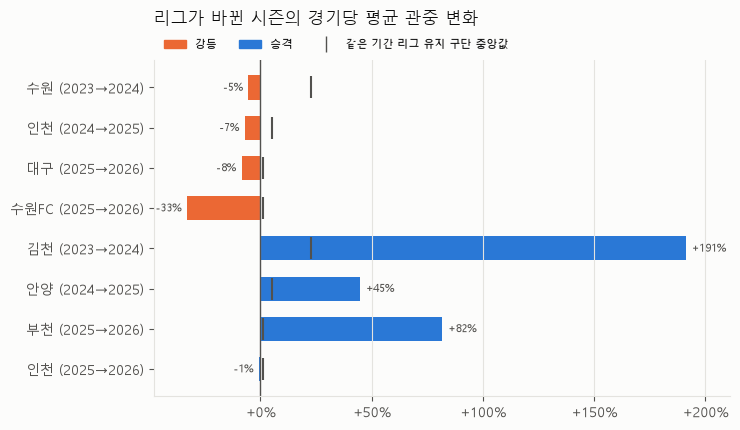

In [5]:
t = chg_tbl.iloc[::-1]
labels = [f"{c} ({s})" for c, s in zip(t["구단"], t["시즌"])]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
bars = ax.barh(labels, t["변화(%)"], color=[ORANGE if k == "강등" else BLUE for k in t["구분"]], height=0.6)
ax.scatter(t["기준선(%)"], range(len(t)), marker="|", s=260, color=INK2, zorder=3)
ax.bar_label(bars, labels=[f"{v:+.0f}%" for v in t["변화(%)"]], padding=4, fontsize=8, color=INK2)
ax.axvline(0, color=INK2, linewidth=1)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0f}%")
ax.grid(axis="y", visible=False)
lo, hi = t["변화(%)"].min(), t["변화(%)"].max()
ax.set_xlim(min(lo, 0) - 15, hi + 20)
handles = [plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE),
           plt.Line2D([], [], color=INK2, marker="|", linestyle="", markersize=12)]
ax.legend(handles, ["강등", "승격", "같은 기간 리그 유지 구단 중앙값"], frameon=False, fontsize=8,
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
ax.set_title("리그가 바뀐 시즌의 경기당 평균 관중 변화", loc="left", fontsize=12, pad=26)
fig.tight_layout(); fig.savefig(FIG / "05_league_change.png", bbox_inches="tight"); plt.show()

## 2. 전체 구단 모형: K리그2에서 성적과 관중의 관계가 다른가

`02_models.ipynb`의 모형 3에 `home_form5 × K리그2` 상호작용을 더한다.
- `home_form5` 계수 = K리그1에서 홈팀 최근 5경기 경기당 승점 +1점과 관중의 관계
- 상호작용 계수 = K리그2에서 그 관계가 얼마나 다른가

In [6]:
FE = "C(home_team) + C(season) + k1 + C(month, Treatment(3))"
M3 = ("C(day_type, Treatment('평일')) + night + rain + hot + cold"
      " + home_rank_pre + away_rank_pre + home_form5 + away_form5 + home_first_game + away_first_game"
      " + ln_away_fans_pre + away_fans_missing + derby + home_opener + last_home + final_round")
groups = df["home_team"].astype("category").cat.codes
m_int = smf.ols(f"ln_attendance ~ {M3} + home_form5:k2 + {FE}", data=df).fit(cov_type="cluster", cov_kwds={"groups": groups})


def slope(m, base, extra=None):
    """base 계수(+ extra 계수)의 % 효과와 95% 구간"""
    b, V = m.params, m.cov_params()
    est = b[base] + (b[extra] if extra else 0)
    var = V.loc[base, base] + ((V.loc[extra, extra] + 2 * V.loc[base, extra]) if extra else 0)
    se = np.sqrt(var)
    return [(np.exp(x) - 1) * 100 for x in (est, est - 1.96 * se, est + 1.96 * se)]


res2 = pd.DataFrame([slope(m_int, "home_form5"), slope(m_int, "home_form5", "home_form5:k2")],
                    index=["K리그1", "K리그2"], columns=["경기당 승점 +1점의 관중 차이(%)", "95% 하한", "95% 상한"]).round(1)
print(f"상호작용(K리그2 - K리그1) 계수 {m_int.params['home_form5:k2']:+.3f}, p = {m_int.pvalues['home_form5:k2']:.3f}")
res2

상호작용(K리그2 - K리그1) 계수 -0.045, p = 0.281


,경기당 승점 +1점의 관중 차이(%),95% 하한,95% 상한
K리그1,9.2,2.1,16.9
K리그2,4.4,-0.3,9.5


## 3. 수원 홈경기만 본 모형 (탐색적)

수원 홈경기 64경기(K리그1 2023: 19경기, K리그2 2024~2026: 45경기)만으로 추정한다.
- 시즌 더미를 넣으므로 K리그2 자체의 효과는 시즌 더미에 들어간다. `home_form5:k2`는 'K리그2 시절 성적 민감도가 K리그1 시절과 얼마나 다른가'다.
- 구단이 하나라 군집 표준오차를 쓸 수 없어 HC3 강건 표준오차를 쓴다.
- 경기 수에 비해 변수가 많아 **탐색적 결과**로만 본다. 모든 경기에서 값이 같은 변수(예: 해당 경기가 하나도 없는 더미)는 자동으로 뺀다.

In [7]:
sw = df[df["home_team"] == "수원"].copy()
terms = ["C(day_type, Treatment('평일'))", "night", "rain", "hot", "cold", "home_form5", "home_form5:k2", "home_first_game",
         "home_rank_pre", "ln_away_fans_pre", "away_fans_missing", "derby", "home_opener", "last_home", "C(season)"]
dropped = [t for t in terms if t.isidentifier() and sw[t].nunique() < 2]
terms = [t for t in terms if t not in dropped]
print("값이 하나뿐이라 뺀 변수:", dropped or "없음")
m_sw = smf.ols("ln_attendance ~ " + " + ".join(terms), data=sw).fit(cov_type="HC3")
print(f"N = {int(m_sw.nobs)}, 수정 R² = {m_sw.rsquared_adj:.3f}")

SW_LABELS = {
    "C(day_type, Treatment('평일'))[T.주말]": "주말 (평일 대비)",
    "C(day_type, Treatment('평일'))[T.평일공휴일]": "평일 공휴일 (평일 대비)",
    "night": "야간 경기", "rain": "경기 시간 비", "hot": "킥오프 30℃ 이상", "cold": "킥오프 5℃ 이하",
    "home_form5": "최근 5경기 경기당 승점 +1점 (K리그1 시절)", "home_form5:k2": "  └ K리그2 시절 추가 차이",
    "home_rank_pre": "순위 1계단 아래로", "ln_away_fans_pre": "원정팬 동원력 (log +1)",
    "derby": "더비", "home_opener": "시즌 첫 홈경기", "last_home": "시즌 마지막 홈경기",
}
tt = pd.DataFrame({"b": m_sw.params, "p": m_sw.pvalues}).loc[[k for k in SW_LABELS if k in m_sw.params.index]]
tt["효과(%)"] = ((np.exp(tt["b"]) - 1) * 100).round(1)
tt["유의"] = tt["p"].map(stars)
tt.index = [SW_LABELS[k] for k in tt.index]
tt[["효과(%)", "p", "유의"]].round(3)

값이 하나뿐이라 뺀 변수: ['cold']
N = 64, 수정 R² = 0.634


,효과(%),p,유의
주말 (평일 대비),70.7,0.000,***
평일 공휴일 (평일 대비),57.8,0.117,
야간 경기,-1.5,0.822,
경기 시간 비,-14.4,0.421,
킥오프 30℃ 이상,29.2,0.028,**
최근 5경기 경기당 승점 +1점 (K리그1 시절),39.7,0.171,
└ K리그2 시절 추가 차이,-27.0,0.249,
순위 1계단 아래로,0.5,0.796,
원정팬 동원력 (log +1),16.6,0.007,***
더비,20.7,0.060,*


In [8]:
k1s = slope(m_sw, "home_form5")
k2s = slope(m_sw, "home_form5", "home_form5:k2")
print(f"수원 K리그1 시절: 경기당 승점 +1점당 {k1s[0]:+.1f}% (95% {k1s[1]:+.1f}% ~ {k1s[2]:+.1f}%)")
print(f"수원 K리그2 시절: 경기당 승점 +1점당 {k2s[0]:+.1f}% (95% {k2s[1]:+.1f}% ~ {k2s[2]:+.1f}%)")

수원 K리그1 시절: 경기당 승점 +1점당 +39.7% (95% -13.5% ~ +125.5%)
수원 K리그2 시절: 경기당 승점 +1점당 +2.0% (95% -9.2% ~ +14.6%)


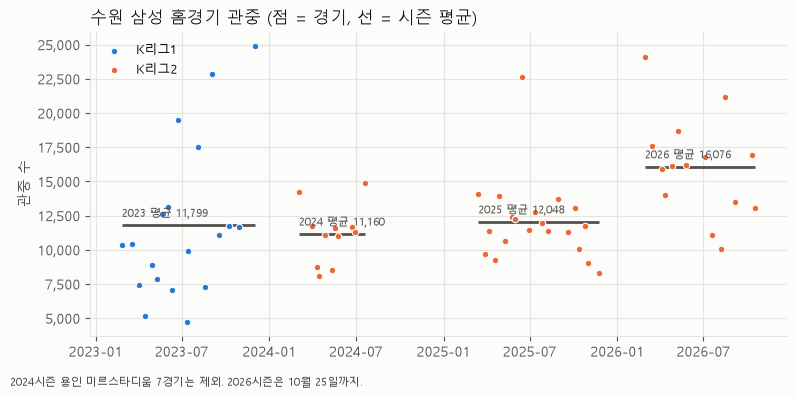

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for lgname, color in [("K리그1", BLUE), ("K리그2", ORANGE)]:
    x = sw[sw["league"] == lgname]
    ax.scatter(x["date"], x["attendance"], s=22, color=color, edgecolor=SURFACE, linewidth=0.8, label=lgname, zorder=3)
for season, g in sw.groupby("season"):
    ax.hlines(g["attendance"].mean(), g["date"].min(), g["date"].max(), color=INK2, linewidth=2)
    ax.annotate(f"{season} 평균 {g['attendance'].mean():,.0f}", (g["date"].min(), g["attendance"].mean()),
                xytext=(0, 6), textcoords="offset points", fontsize=8, color=INK2)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_ylabel("관중 수")
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.set_title("수원 삼성 홈경기 관중 (점 = 경기, 선 = 시즌 평균)", loc="left", fontsize=12)
fig.text(0.01, -0.03, "2024시즌 용인 미르스타디움 7경기는 제외. 2026시즌은 10월 25일까지.", fontsize=8, color=INK2)
fig.tight_layout(); fig.savefig(FIG / "06_suwon_matches.png", bbox_inches="tight"); plt.show()

## 해석

**1. 리그 변경 전후 비교**
- 강등된 4개 구단은 모두 관중이 줄었다(−5%~−33%). 수원(−5%)은 가장 적게 줄었지만, 2023→2024는 리그 전체 관중이 크게 는 해(리그 유지 구단 중앙값 +23%)라 상대적으로는 가장 크게 뒤처졌다(−28%p).
- 승격 구단은 대체로 크게 늘었다(부천 +82%, 안양 +45%). 김천(+191%)은 군 팀이라는 특수성이 있고, 인천(2026, −1%)은 한 시즌 만에 돌아와 원래 수준을 유지한 경우다.
- 수원은 강등 뒤 해마다 관중이 늘어 2026년에는 K리그1 시절(2023)보다 36% 많았다. 2026년에는 대구·수원FC가 K리그2로 내려와 '수원 더비'와 인기 원정팀 경기가 늘어난 것도 관련이 있을 수 있다(모형 3의 원정 팬·더비 효과).

**2. 전체 구단: K리그2의 성적 민감도**
- 홈팀 최근 5경기 경기당 승점 +1점당 관중은 K리그1 +9.2%, K리그2 +4.4%였다. K리그2에서 더 작지만 차이는 통계적으로 뚜렷하지 않다(p=0.28).

**3. 수원 홈경기 모형 (탐색적)**
- K리그2 시절 성적 민감도는 +2%로 사실상 0에 가깝다. K리그1 시절(+40%)은 구간이 매우 넓어(−14%~+126%) 판단하기 어렵다.
- 원정 팬 동원력이 높은 상대와의 경기(log +1당 +17%, 수원 모형 기준)와 주말(+71%)은 뚜렷했다.
- 킥오프 30℃ 이상 +29%(p=0.03)는 전체 모형(+0%)과 반대 방향이다. 64경기 중 소수 경기에 좌우됐을 가능성이 커 해석하지 않는다(여름방학 기간 경기 등 다른 요인이 섞였을 수 있다).

**한계**
- 수원 2024시즌은 용인 미르스타디움 7경기가 빠져 11경기만 남았다. 강등 첫해 평균은 시즌 전반부(3~7월) 경기 위주다.
- 기준선은 K리그1·2를 가리지 않고 리그를 유지한 구단 전체의 중앙값이다. K리그2 구단들의 관중이 빠르게 늘던 시기라 강등 구단에게 불리한 기준일 수 있다.
- 수원 모형은 64경기에 변수가 많고, 구단이 하나라 군집 표준오차를 쓸 수 없다. 개별 계수보다 방향과 크기 정도만 참고한다.

## 구단 마케팅 담당자가 할 수 있는 일 (예시)

> **예시입니다.** 아래 제안은 분석 결과에서 떠올린 아이디어로, 실제 효과가 확인된 것은 아닙니다. 실제 제안은 다른 리그·구단의 성공 사례를 근거로 다시 작성할 예정이며, 사례는 `docs/benchmark_cases.md`에 모으고 있습니다.

| 결과 | 할 수 있는 일 (예시) |
| --- | --- |
| 강등 직후에는 관중이 리그 흐름보다 뒤처짐 | 강등 확정 직후 시즌권 조기 갱신 혜택, '다시 올라간다' 스토리텔링으로 이탈 막기 |
| K리그2 시절 관중이 성적과 거의 무관 | 성적 홍보보다 경기장 경험·팬 커뮤니티 투자에 예산 배분 |
| 원정 팬 동원력이 높은 상대·더비 경기 관중 증가 | 강등 구단끼리의 경기, 지역 더비를 시즌 핵심 경기로 묶어 패키지 판매 |
